# Laboratorium 3 — Otwarte dane i wartości odstające

**Eksploracja danych** · dr Paweł Gliwny · WFiIS UŁ

Na tych zajęciach:

1. **Część 1** — pobierzesz dane z portalu otwartych danych Łodzi, wczytasz je, zmienisz ich format, policzysz statystyki zbiorcze i zrobisz proste wykresy.
2. **Część 2** — na danych o pacjentach przejdziesz kolejne kroki wykrywania wartości odstających: od najprostszych do bardziej złożonych.

Miejsca do uzupełnienia oznaczone są `# TODO`. Odpowiedzi na pytania wpisuj w komórkach tekstowych oznaczonych ✍️.

> Notatnik po zajęciach umieść w swoim repozytorium na GitHubie.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.float_format", "{:.2f}".format)
plt.rcParams["figure.dpi"] = 100

In [2]:
def upewnij_sie_ze_jest(nazwa_pliku):
    # W Colabie: jeśli pliku nie ma, otwiera okno wgrywania pliku.
    if Path(nazwa_pliku).exists():
        print(f"Plik {nazwa_pliku} jest na miejscu.")
        return
    try:
        from google.colab import files
        print(f"Wgraj plik {nazwa_pliku}:")
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"Umieść plik {nazwa_pliku} w folderze z notatnikiem.")

---
# Część 1. Dane z portalu otwartych danych Łodzi

Portal: [otwarte.miasto.lodz.pl](https://otwarte.miasto.lodz.pl)

Zaczynamy od wspólnego przykładu — pliku `szkolnictwo_wysze.csv` (szkolnictwo wyższe w Łodzi w latach 2012–2024). Pobierz go z portalu albo od prowadzącego i wgraj do Colaba (ikona folderu po lewej lub komórka poniżej).

In [3]:
PLIK_LODZ = "szkolnictwo_wysze.csv"
upewnij_sie_ze_jest(PLIK_LODZ)

Plik szkolnictwo_wysze.csv jest na miejscu.


## 1.1 Wczytanie danych

Zanim wywołasz `read_csv`, obejrzyj surowy plik — pierwsze linie tekstu powiedzą, jaki jest separator.

In [4]:
# podgląd surowego pliku
with open(PLIK_LODZ, encoding="utf-8") as f:
    for _ in range(5):
        print(f.readline().rstrip())

name;rok;wartość;zmienna
Szkolnictwo wyższe;2012;22;uczelnie
Szkolnictwo wyższe;2013;22;uczelnie
Szkolnictwo wyższe;2014;23;uczelnie
Szkolnictwo wyższe;2015;21;uczelnie


In [5]:
# TODO: wczytaj plik do ramki `df` z właściwym separatorem
with open(PLIK_LODZ, encoding="utf-8-sig") as f:
    naglowek = f.readline()
separator = ";" if naglowek.count(";") > naglowek.count(",") else ","
df = pd.read_csv(PLIK_LODZ, sep=separator, encoding="utf-8-sig")
df.columns = df.columns.str.strip()
if "wartość" in df:
    df["wartość"] = pd.to_numeric(
        df["wartość"].astype(str).str.replace(" ", "", regex=False)
          .str.replace(",", ".", regex=False), errors="coerce"
    )
print("Separator:", repr(separator))
print(df.head())
print("Wymiary:", df.shape)
print(df.dtypes)

# TODO: wyświetl pierwsze wiersze, wymiary i typy kolumn


Separator: ';'
                 name   rok  wartość   zmienna
0  Szkolnictwo wyższe  2012       22  uczelnie
1  Szkolnictwo wyższe  2013       22  uczelnie
2  Szkolnictwo wyższe  2014       23  uczelnie
3  Szkolnictwo wyższe  2015       21  uczelnie
4  Szkolnictwo wyższe  2016       20  uczelnie
Wymiary: (65, 4)
name         str
rok        int64
wartość    int64
zmienna      str
dtype: object


✍️ **Pytanie:** Jaki jest separator? Czy kolumna `wartość` ma typ liczbowy? Czy nazwy kolumn z polskimi znakami wczytały się poprawnie?

*Odpowiedź:* Separatorem jest średnik. Typ `wartość` jest konwertowany na liczbowy. Wartości z polskimi znakami wczytały się poprawnie.

## 1.2 Format długi czy szeroki?

Przypomnienie z wykładu 2: w formacie **długim** każdy wiersz to jedna para (zmienna, wartość); w formacie **szerokim** każda zmienna ma własną kolumnę.

1. Sprawdź, jakie wartości przyjmuje kolumna `zmienna` i ile razy każda występuje.
2. Przekształć dane do formatu szerokiego: wiersze = lata, kolumny = zmienne.

In [6]:
# TODO: jakie są zmienne i ile mają wierszy?

print("Liczebności zmiennych:")
print(df["zmienna"].value_counts(dropna=False))
# TODO: format szeroki (pivot) — wynik zapisz w `szeroka`
szeroka = df.pivot_table(index="rok", columns="zmienna", values="wartość", aggfunc="first")
szeroka.index = pd.to_numeric(szeroka.index)
szeroka = szeroka.sort_index()
print(szeroka)

Liczebności zmiennych:
zmienna
uczelnie             13
ogółem               13
kobiety              13
mężczyźni            13
absolwenci ogółem    13
Name: count, dtype: int64
zmienna  absolwenci ogółem  kobiety  mężczyźni  ogółem  uczelnie
rok                                                             
2012                 24825    55265      36281   91546        22
2013                 22590    50007      33464   83471        22
2014                 21343    48220      32456   80676        23
2015                 19835    45584      30769   76353        21
2016                 17662    44053      29908   73961        20
2017                 19281    42990      29029   72019        22
2018                 17046    39312      26253   65565        20
2019                 15819    38146      26297   64443        19
2020                 14082    39170      26155   65325        18
2021                 14756    39958      26044   66002        17
2022                 14479    38484      26

## 1.3 Czy dane są spójne?

Liczba studentów `ogółem` powinna być sumą `kobiety` i `mężczyźni`. Sprawdź to dla każdego roku.

In [10]:
# TODO: policz różnicę (kobiety + mężczyźni) − ogółem dla każdego roku
kol_kobiety = "kobiety"
kol_mezczyzni = "mężczyźni"
kol_ogolem = "ogółem"
kol_uczelnie = "uczelnie"
roznica = szeroka[kol_kobiety] + szeroka[kol_mezczyzni] - szeroka[kol_ogolem]
print("Różnica dla każdego roku:")
print(roznica)
print("Wszystkie zgodne:", roznica.dropna().eq(0).all())

Różnica dla każdego roku:
rok
2012    0
2013    0
2014    0
2015    0
2016    0
2017    0
2018    0
2019    0
2020    0
2021    0
2022    0
2023    0
2024    0
dtype: int64
Wszystkie zgodne: True


## 1.4 Statystyki zbiorcze

1. Policz statystyki opisowe dla wszystkich zmiennych (`describe`).
2. O ile procent zmieniła się każda zmienna między 2012 a 2024 rokiem?
3. Dodaj kolumnę `udzial_kobiet` (udział kobiet wśród studentów) i kolumnę `studenci_na_uczelnie`.

In [11]:
# TODO: statystyki opisowe
print("Statystyki opisowe:")
print(szeroka.describe())
# TODO: zmiana procentowa 2012 → 2024
zmiana_proc = (szeroka.loc[2024] / szeroka.loc[2012] - 1) * 100
print("Zmiana procentowa 2012–2024:")
print(zmiana_proc.round(2))
# TODO: nowe kolumny
szeroka["udzial_kobiet"] = szeroka[kol_kobiety] / szeroka[kol_ogolem].replace(0, np.nan)
szeroka["studenci_na_uczelnie"] = szeroka[kol_ogolem] / szeroka[kol_uczelnie].replace(0, np.nan)
print(szeroka[["udzial_kobiet", "studenci_na_uczelnie"]])

Statystyki opisowe:
zmienna  absolwenci ogółem  kobiety  mężczyźni   ogółem  uczelnie
count                13.00    13.00      13.00    13.00     13.00
mean              17780.54 43010.92   28793.92 71804.85     19.54
std                3522.40  5391.05    3524.63  8900.65      2.44
min               14082.00 38146.00   25710.00 64272.00     15.00
25%               14756.00 39170.00   26049.00 65297.00     18.00
50%               17046.00 39958.00   26297.00 66002.00     20.00
75%               19835.00 45584.00   30769.00 76353.00     22.00
max               24825.00 55265.00   36281.00 91546.00     23.00
Zmiana procentowa 2012–2024:
zmienna
absolwenci ogółem   -41.29
kobiety             -30.22
mężczyźni           -29.14
ogółem              -29.79
uczelnie            -31.82
dtype: float64
zmienna  udzial_kobiet  studenci_na_uczelnie
rok                                         
2012              0.60               4161.18
2013              0.60               3794.14
2014              0

## 1.5 Wykresy

Narysuj trzy wykresy (najlepiej obok siebie, `plt.subplots(1, 3)`):

1. liczba studentów w czasie — osobne linie dla kobiet i mężczyzn,
2. liczba uczelni w czasie,
3. udział kobiet wśród studentów (oś Y od 0 do 1).

Każdy wykres podpisz: tytuł, opisy osi.

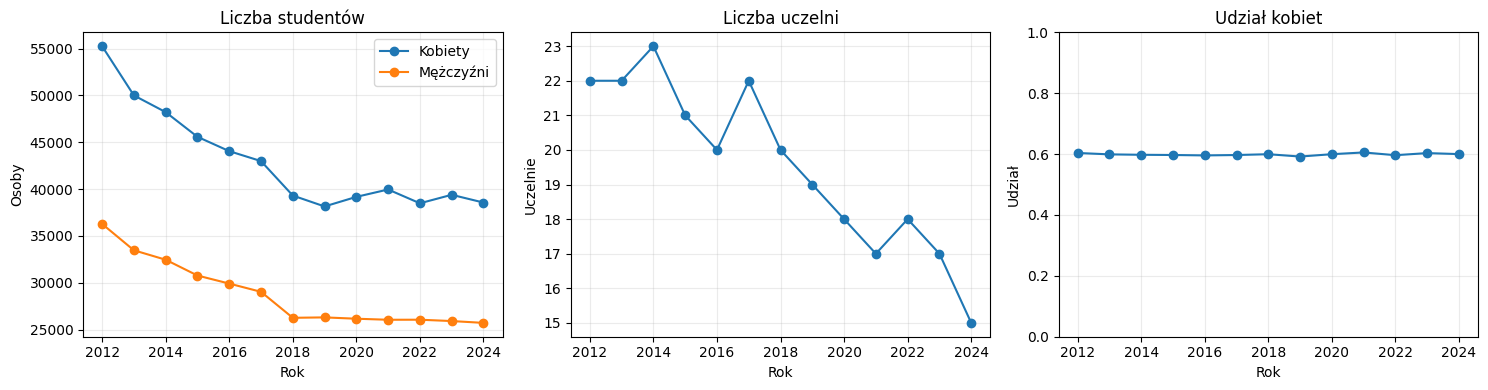

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# TODO: wykres 1 — kobiety i mężczyźni
axes[0].plot(szeroka.index, szeroka[kol_kobiety], marker="o", label="Kobiety")
axes[0].plot(szeroka.index, szeroka[kol_mezczyzni], marker="o", label="Mężczyźni")

# TODO: wykres 2 — uczelnie
axes[0].set(title="Liczba studentów", xlabel="Rok", ylabel="Osoby")
axes[0].legend()
axes[1].plot(szeroka.index, szeroka[kol_uczelnie], marker="o")
axes[1].set(title="Liczba uczelni", xlabel="Rok", ylabel="Uczelnie")

# TODO: wykres 3 — udział kobiet
axes[2].plot(szeroka.index, szeroka["udzial_kobiet"], marker="o")
axes[2].set(title="Udział kobiet", xlabel="Rok", ylabel="Udział", ylim=(0, 1))
for ax in axes: ax.grid(alpha=.25)
plt.tight_layout()
plt.show()

✍️ **Wnioski** (3 zdania): co się stało ze szkolnictwem wyższym w Łodzi w latach 2012–2024?

*Odpowiedź:* Liczba studentrów znaczne zmalała w tych latach, liczba uczelni zwykle też malała ale miała trzy odbicia gdzie wzrosła. Jednak spadek jest ciągły. Udział kobiet nie zmienił się znacznie cały czas jest praktycznie stały.

## 1.6 Zadanie samodzielne: Twój zbiór z portalu Łodzi

Wybierz **inny** zbiór z [otwarte.miasto.lodz.pl](https://otwarte.miasto.lodz.pl) i przejdź te same kroki:

1. Podaj nazwę zbioru, link i datę pobrania.
2. Wczytaj plik (separator? kodowanie? przecinek dziesiętny?).
3. Ustal, czy dane są w formacie długim, czy szerokim; w razie potrzeby przekształć.
4. Sprawdź braki (`isna().sum()`) i spójność danych.
5. Policz statystyki zbiorcze.
6. Zrób 2–3 podpisane wykresy i napisz 2–3 zdania wniosków.

✍️ **Zbiór:** … · **link:** … · **data pobrania:** …

In [13]:
# TODO: wczytanie i przegląd Twojego zbioru
import base64
from pathlib import Path
PLIK_INNY = "dochody-miasta-na-1-mieszkaca.csv"
inny = pd.read_csv(PLIK_INNY, sep=";", encoding="utf-8-sig", decimal=",")
inny.columns = inny.columns.str.strip()
inny["wartość"] = pd.to_numeric(inny["wartość"], errors="coerce")
print("Wymiary:", inny.shape)
print("Kolumny i typy:\n", inny.dtypes)
print("Braki:\n", inny.isna().sum())
print("Pierwsze wiersze:\n", inny.head())

Wymiary: (23, 5)
Kolumny i typy:
 id           int64
name           str
rok          int64
wartość    float64
zmienne        str
dtype: object
Braki:
 id         0
name       0
rok        0
wartość    0
zmienne    0
dtype: int64
Pierwsze wiersze:
       id               name   rok  wartość                         zmienne
0  76974  Finanse Publiczne  2002  1941.00  dochody miasta na 1 mieszkańca
1  76974  Finanse Publiczne  2003  1936.00  dochody miasta na 1 mieszkańca
2  76974  Finanse Publiczne  2004  2173.00  dochody miasta na 1 mieszkańca
3  76974  Finanse Publiczne  2005  2397.00  dochody miasta na 1 mieszkańca
4  76974  Finanse Publiczne  2006  2761.06  dochody miasta na 1 mieszkańca


Statystyki dochodów na mieszkańca:
 count      23.00
mean     4968.07
std      2359.29
min      1936.00
25%      3225.93
50%      4793.75
75%      6264.26
max     10253.68
Name: wartość, dtype: float64
Duplikaty wierszy: 0
Powtórzone lata: 0
Lata: 2002 – 2024
Format: długi (kolumny 'zmienne' i 'wartość')
Tabela szeroka:
 zmienne  dochody miasta na 1 mieszkańca
rok                                    
2002                            1941.00
2003                            1936.00
2004                            2173.00
2005                            2397.00
2006                            2761.06
Zmiana 2002–2024: 428.27%


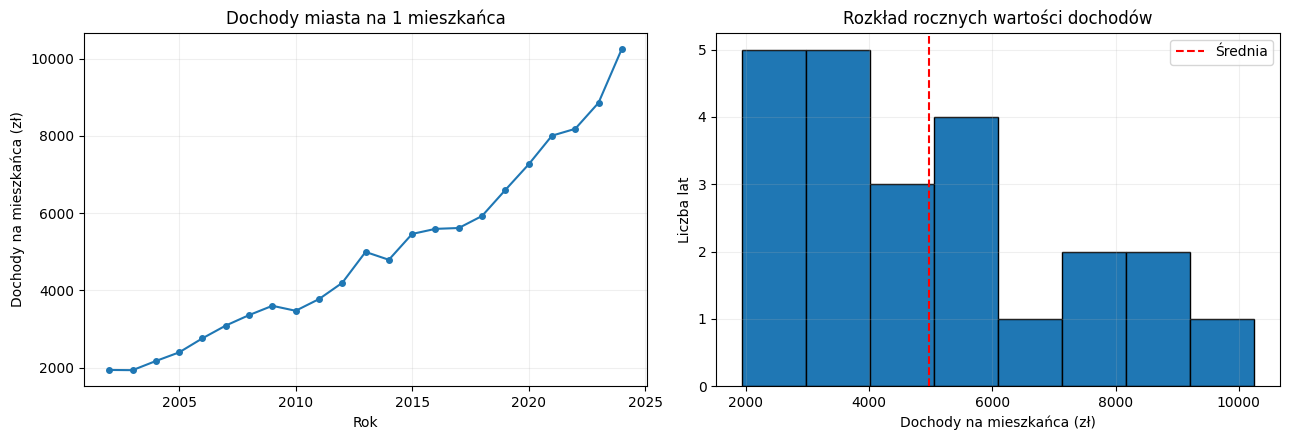

In [21]:
# TODO: przekształcenia, statystyki i wykresy
print("Statystyki dochodów na mieszkańca:\n", inny["wartość"].describe())
print("Duplikaty wierszy:", inny.duplicated().sum())
print("Powtórzone lata:", inny["rok"].duplicated().sum())
print("Lata:", inny["rok"].min(), "–", inny["rok"].max())
print("Format: długi (kolumny 'zmienne' i 'wartość')")

inny_szeroki = inny.pivot(index="rok", columns="zmienne", values="wartość")
print("Tabela szeroka:\n", inny_szeroki.head())

pierwsza = inny.sort_values("rok").iloc[0]
ostatnia = inny.sort_values("rok").iloc[-1]
zmiana = (ostatnia["wartość"] / pierwsza["wartość"] - 1) * 100
print(f"Zmiana {int(pierwsza['rok'])}–{int(ostatnia['rok'])}: {zmiana:.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(inny["rok"], inny["wartość"], marker="o", markersize=4)
axes[0].set(title="Dochody miasta na 1 mieszkańca", xlabel="Rok", ylabel="Dochody na mieszkańca (zł)")
axes[1].hist(inny["wartość"], bins=8, edgecolor="black")
axes[1].axvline(inny["wartość"].mean(), linestyle="--", color="red", label="Średnia")
axes[1].set(title="Rozkład rocznych wartości dochodów", xlabel="Dochody na mieszkańca (zł)", ylabel="Liczba lat")
axes[1].legend()
for ax in axes: ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

✍️ **Wnioski:** …

---
# Część 2. Wartości odstające — dane o pacjentach

Zbiór: 3000 pacjentów z kolumnami `age` (wiek), `bmi`, `avg_glucose_level` (średni poziom glukozy we krwi, mg/dl), `hypertension`, `heart_disease`, `work_type` (rodzaj pracy), `smoking_status` (palenie), `stroke` (udar: 1/0) i kilkoma innymi.

> ⚠️ To **dane syntetyczne** — wygenerowane i celowo „zepsute” do ćwiczeń. Nie wyciągamy z nich wniosków medycznych.
>
> Źródło: deepsense.ai, *EDA Benchmark*, zadanie `identify-unusual-values` ([github.com/deepsense-ai/eda-benchmark](https://github.com/deepsense-ai/eda-benchmark)), licencja CC BY-NC-ND 4.0.

Plan — od najprostszej metody do najbardziej złożonej:

| Krok | Metoda |
|---|---|
| 1 | wartości niemożliwe — progi z wiedzy dziedzinowej |
| 2 | wartości skrajne w jednej zmiennej — wykresy, potem IQR, z-score, MAD |
| 3 | nielogiczne kombinacje kategorii — reguły |
| 4 | nietypowe kombinacje liczb — odległość od środka |
| 5 | decyzja: co zrobić z każdą grupą |

In [15]:
URL = ("https://raw.githubusercontent.com/deepsense-ai/eda-benchmark/main/"
       "tasks/identify-unusual-values/environment/dataset/synthetic_stroke_data.csv")

pacjenci = pd.read_csv(URL)
oryginal = pacjenci.copy()      # kopia surowych danych — przyda się na końcu
pacjenci.head()

,patient_id,gender,age,hypertension,heart_disease,ever_married,work_type,residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,A456281,Male,25.00,0,0,False,student,Urban,77.47,35.66,formerly smoked,0
1,A730553,Male,16.00,0,0,True,student,Urban,83.78,34.76,never smoked,0
2,A800980,Male,19.00,0,0,True,Private,Urban,91.65,25.38,never smoked,0
3,A433166,Male,35.00,0,0,True,Self-employed,Urban,97.09,21.26,never smoked,0
4,A114521,Male,15.00,0,0,True,student,Urban,89.17,22.27,formerly smoked,0


## 2.0 Pierwszy rzut oka

Wyświetl statystyki opisowe kolumn liczbowych `age`, `bmi`, `avg_glucose_level` i narysuj ich histogramy.

          age     bmi  avg_glucose_level
count 3000.00 3000.00            3000.00
mean    45.25   26.29             134.00
std     20.83   15.88             181.27
min      0.67   -5.20             -21.40
25%     28.00   21.28              85.59
50%     49.00   24.70             101.40
75%     63.00   28.88             127.43
max     80.00  105.60            1254.60


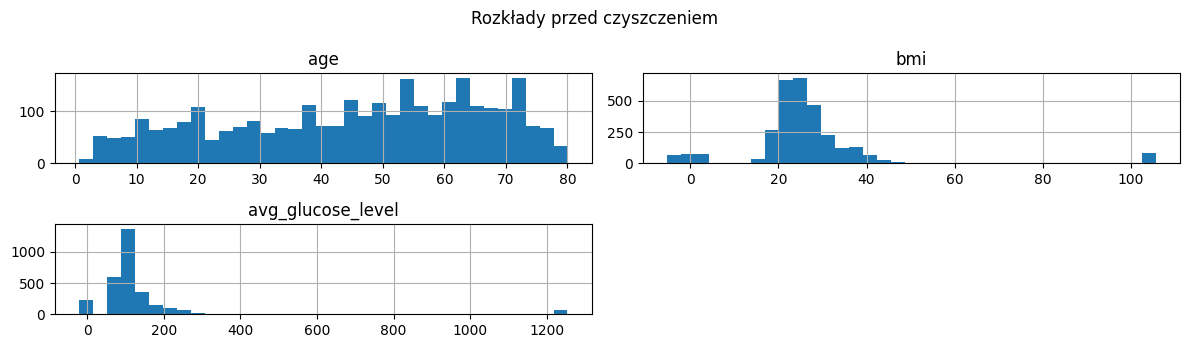

In [16]:
LICZBOWE = ["age", "bmi", "avg_glucose_level"]

# TODO: statystyki opisowe
print(pacjenci[LICZBOWE].describe())

# TODO: histogramy (np. pacjenci[LICZBOWE].hist(...))
pacjenci[LICZBOWE].hist(bins=35, figsize=(12, 3.5))
plt.suptitle("Rozkłady przed czyszczeniem")
plt.tight_layout()
plt.show()

✍️ **Pytanie:** Które wartości minimalne i maksymalne są w ogóle *możliwe* u człowieka?

*Odpowiedź:* Wiek człowieka na wykresie jest całościowo możliwy. Natomiast dla bmi minimalna i maksymalna wskazana jest nie możliwa dla człowieka. avg_glucose_level maksymalna i minimalna też jest możliwa.

## 2.1 Krok 1: wartości niemożliwe

Przyjmujemy progi:

| Zmienna | Zakres możliwy |
|---|---|
| `bmi` | 10–60 |
| `avg_glucose_level` | 20–800 mg/dl |
| `age` | 0–120 lat |

Wartości spoza zakresu to **szum techniczny**, a nie rzadcy pacjenci — zamieniamy je na `NaN`.

1. Utwórz maski `zle_bmi`, `zla_glukoza`, `zly_wiek` (przyda się `Series.between`).
2. Policz, ile wartości jest niemożliwych w każdej kolumnie i ilu pacjentów ma co najmniej jedną taką wartość.
3. Zamień niemożliwe wartości na `NaN`.

In [17]:
# TODO: maski
zle_bmi = pacjenci["bmi"].notna() & ~pacjenci["bmi"].between(10, 60)
zla_glukoza = pacjenci["avg_glucose_level"].notna() & ~pacjenci["avg_glucose_level"].between(20, 800)
zly_wiek = pacjenci["age"].notna() & ~pacjenci["age"].between(0, 120)

# TODO: liczebności
niemozliwe = zle_bmi | zla_glukoza | zly_wiek
print(pd.Series({"BMI": zle_bmi.sum(), "glukoza": zla_glukoza.sum(),
                 "wiek": zly_wiek.sum(), "pacjenci z co najmniej jedną": niemozliwe.sum()}))

# TODO: zamiana na NaN
pacjenci.loc[zle_bmi, "bmi"] = np.nan
pacjenci.loc[zla_glukoza, "avg_glucose_level"] = np.nan
pacjenci.loc[zly_wiek, "age"] = np.nan

BMI                             300
glukoza                         300
wiek                              0
pacjenci z co najmniej jedną    560
dtype: int64


          age     bmi  avg_glucose_level
count 3000.00 2700.00            2700.00
mean    45.25   26.12             116.84
std     20.83    5.84              44.45
min      0.67   13.57              44.76
25%     28.00   21.94              89.47
50%     49.00   24.98             103.09
75%     63.00   28.85             127.84
max     80.00   47.62             332.91


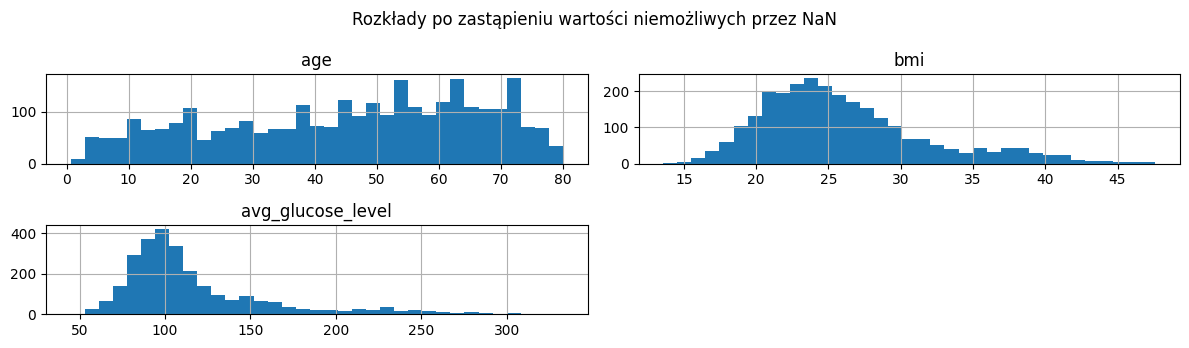

In [18]:
# TODO: ponownie statystyki opisowe i histogramy — co się zmieniło?
print(pacjenci[LICZBOWE].describe())
pacjenci[LICZBOWE].hist(bins=35, figsize=(12, 3.5))
plt.suptitle("Rozkłady po zastąpieniu wartości niemożliwych przez NaN")
plt.tight_layout()
plt.show()

## 2.2 Krok 2a: wartości skrajne w jednej zmiennej — wykresy

Zanim cokolwiek policzysz, **obejrzyj** dane.

1. Narysuj obok siebie poziome wykresy pudełkowe dla `bmi` i `avg_glucose_level` (`plt.subplots(1, 2)`, `ax.boxplot(..., orientation="horizontal")`). Pamiętaj o `dropna()`.
2. Narysuj obok siebie dwa wykresy punktowe: `age` × `avg_glucose_level` i `age` × `bmi`.

Podpisz osie (z jednostkami) i nadaj tytuły.

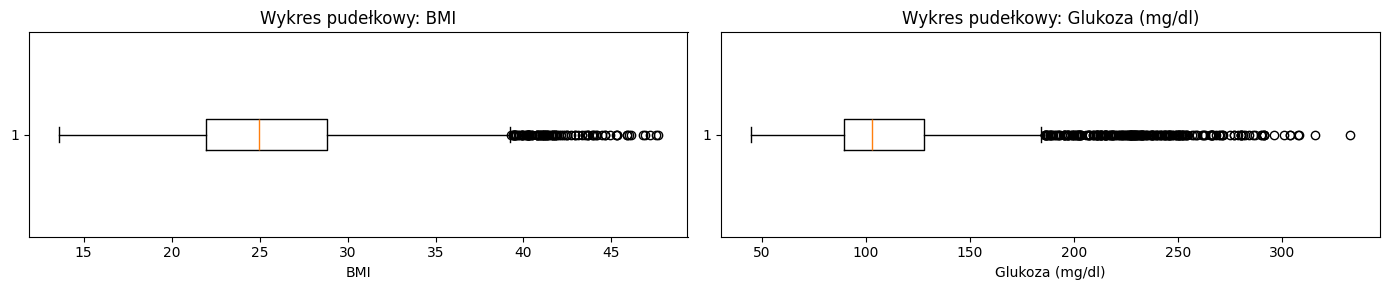

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3))

# TODO: wykresy pudełkowe bmi i glukozy
for ax, col, opis in zip(axes, ["bmi", "avg_glucose_level"], ["BMI", "Glukoza (mg/dl)"]):
    ax.boxplot(pacjenci[col].dropna(), vert=False)
    ax.set(title=f"Wykres pudełkowy: {opis}", xlabel=opis)
plt.tight_layout()
plt.show()

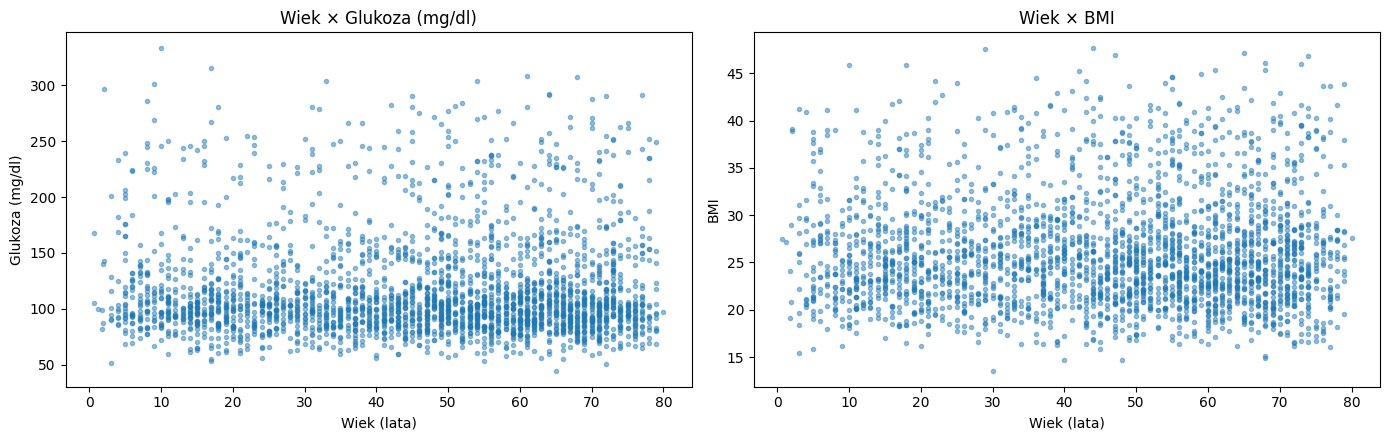

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# TODO: wykresy punktowe age × glukoza i age × bmi
for ax, col, opis in zip(axes, ["avg_glucose_level", "bmi"], ["Glukoza (mg/dl)", "BMI"]):
    ax.scatter(pacjenci["age"], pacjenci[col], s=9, alpha=.45)
    ax.set(title=f"Wiek × {opis}", xlabel="Wiek (lata)", ylabel=opis)

plt.tight_layout()
plt.show()

✍️ **Pytania:**
1. Dla której zmiennej jest więcej punktów poza wąsami? Czy leżą po obu stronach pudełka, czy tylko po jednej?
2. Na wykresie punktowym: czy wysokie wartości glukozy występują tylko w określonym wieku? Czy 10-latek ze średnią glukozą ponad 300 mg/dl to błąd, czy rzadki przypadek?

*Odpowiedź:* Przy prawoskośnej glukozie wartości skrajne powinny występować przede wszystkim powyżej górnego wąsa. Sam przypadek 10-latka z glukozą ponad 300 mg/dl nie dowodzi błędu — wymaga weryfikacji, a nie automatycznego usunięcia.

## 2.3 Krok 2b: wartości skrajne w jednej zmiennej — metody liczbowe

Napisz trzy funkcje, które dla kolumny `s` zwracają maskę (`True` = wartość odstająca):

- `maska_iqr(s, k=1.5)` — poza $[Q_1 - k \cdot IQR,\; Q_3 + k \cdot IQR]$,
- `maska_z(s, prog=3)` — $|z| > prog$, gdzie $z = (x - \bar{x}) / s$,
- `maska_mad(s, prog=3.5)` — odporny z-score $|0{,}6745 \cdot (x - \text{med}) / \text{MAD}| > prog$.

Braki (`NaN`) nie powinny być oznaczane jako odstające.

In [22]:
def maska_iqr(s, k=1.5):
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    return (s.notna() & ((s < q1 - k * iqr) | (s > q3 + k * iqr))).fillna(False)

def maska_z(s, prog=3):
    sd = s.std()
    if pd.isna(sd) or sd == 0:
        return pd.Series(False, index=s.index)
    return (s.notna() & ((s - s.mean()).abs() / sd > prog)).fillna(False)

def maska_mad(s, prog=3.5):
    med = s.median()
    mad = (s - med).abs().median()
    if pd.isna(mad) or mad == 0:
        return pd.Series(False, index=s.index)
    return (s.notna() & (0.6745 * (s - med).abs() / mad > prog)).fillna(False)

Zbuduj tabelę porównawczą: wiersze = zmienne (`age`, `bmi`, `avg_glucose_level`), kolumny = metody (IQR 1,5, IQR 3, z-score, MAD), wartości = liczba wykrytych obserwacji. Dodaj kolumnę ze **skośnością** (`skew`).

In [23]:
# TODO: tabela porównawcza `porownanie`
porownanie = pd.DataFrame({
    "IQR 1,5": [maska_iqr(pacjenci[c], 1.5).sum() for c in LICZBOWE],
    "IQR 3": [maska_iqr(pacjenci[c], 3).sum() for c in LICZBOWE],
    "z-score": [maska_z(pacjenci[c]).sum() for c in LICZBOWE],
    "MAD": [maska_mad(pacjenci[c]).sum() for c in LICZBOWE],
    "skośność": [pacjenci[c].skew() for c in LICZBOWE],
}, index=LICZBOWE)
print(porownanie)

                   IQR 1,5  IQR 3  z-score  MAD  skośność
age                      0      0        0    0     -0.33
bmi                    100      0       23   33      0.99
avg_glucose_level      235     81       62  223      1.80


✍️ **Pytanie:** Dlaczego dla glukozy metody dają tak różne wyniki, a dla wieku żadna nic nie wykrywa? Spójrz na skośność i histogramy.

*Odpowiedź:* Glukoza ma prawostronny, długi ogon, dlatego średnia i odchylenie standardowe są wrażliwe na skrajne wartości, podczas gdy IQR i MAD są odporniejsze. Wiek ma zwykle bardziej ograniczony rozkład i nie musi przekraczać żadnego z przyjętych progów. Konkretne liczby i skośność pokazuje tabela porownanie

### Wykres: zaznacz wartości odstające

Powtórz wykres punktowy `age` × `avg_glucose_level`, ale tym razem:

- zaznacz innym kolorem pacjentów, których glukoza jest odstająca według `maska_iqr` (i podaj ich liczbę w legendzie),
- narysuj poziomą linię przerywaną na górnej granicy $Q_3 + 1{,}5 \cdot IQR$ (`ax.axhline`).

Sprawdź: czy liczba punktów nad linią zgadza się z liczbą punktów poza wąsem na wykresie pudełkowym?

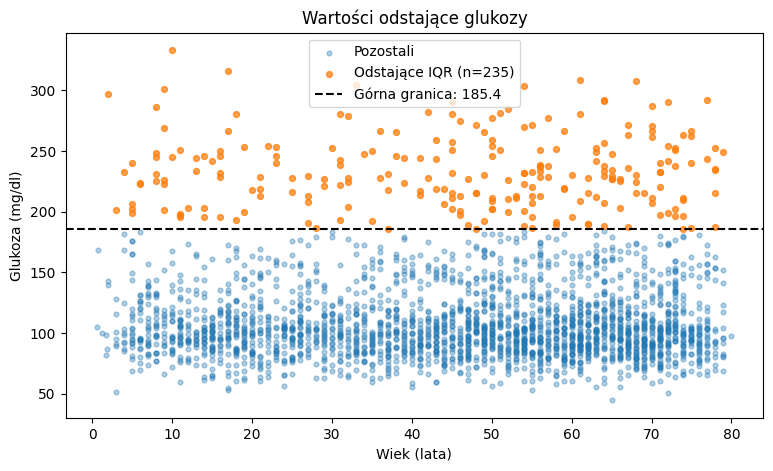

In [24]:
# TODO: wykres punktowy z zaznaczonymi wartościami odstającymi
m_glukoza = maska_iqr(pacjenci["avg_glucose_level"])
q1, q3 = pacjenci["avg_glucose_level"].quantile([.25, .75])
gorna = q3 + 1.5 * (q3 - q1)
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(pacjenci.loc[~m_glukoza, "age"], pacjenci.loc[~m_glukoza, "avg_glucose_level"],
           s=12, alpha=.35, label="Pozostali")
ax.scatter(pacjenci.loc[m_glukoza, "age"], pacjenci.loc[m_glukoza, "avg_glucose_level"],
           s=18, alpha=.75, label=f"Odstające IQR (n={m_glukoza.sum()})")
ax.axhline(gorna, linestyle="--", color="black", label=f"Górna granica: {gorna:.1f}")
ax.set(xlabel="Wiek (lata)", ylabel="Glukoza (mg/dl)", title="Wartości odstające glukozy")
ax.legend()
plt.show()

### Czy wartość odstająca niesie informację?

Wysoki poziom glukozy może być związany z udarem. Porównaj odsetek udarów (`stroke`) wśród pacjentów z glukozą odstającą (IQR 1,5) i wśród pozostałych. Narysuj wykres pudełkowy glukozy w podziale na `stroke`.

Odsetek udarów (w %):
                   count  mean  procent_udarow
avg_glucose_level                             
False               2765  0.22           21.92
True                 235  0.22           21.70


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_6420\4121174628.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(grupy, labels=["Bez udaru", "Udar"])


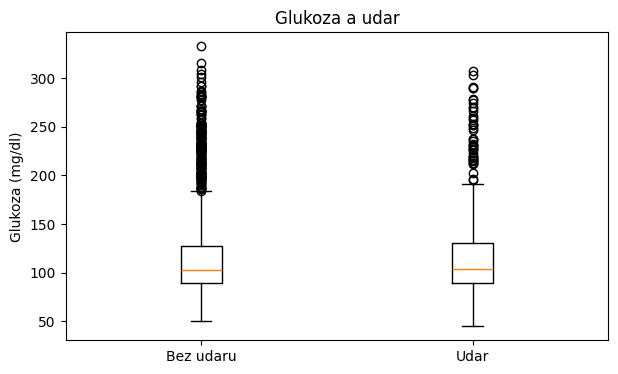

In [ ]:
# TODO: odsetek udarów w obu grupach
m_glukoza = maska_iqr(pacjenci["avg_glucose_level"])
print("Odsetek udarów (w %):")
print(pacjenci.groupby(m_glukoza)["stroke"].agg(["count", "mean"]).assign(
    procent_udarow=lambda t: 100 * t["mean"]))
fig, ax = plt.subplots(figsize=(7, 4))

# TODO: boxplot glukozy w podziale na stroke
grupy = [pacjenci.loc[pacjenci["stroke"] == v, "avg_glucose_level"].dropna() for v in [0, 1]]
ax.boxplot(grupy, labels=["Bez udaru", "Udar"])
ax.set(title="Glukoza a udar", ylabel="Glukoza (mg/dl)")
plt.show()

✍️ **Pytanie:** Czy pacjentów z wysoką glukozą należy usunąć z danych, jeśli chcemy przewidywać udar?

*Odpowiedź:* Nie należy automatycznie usuwać pacjentów z wysoką, lecz możliwą glukozą, ponieważ może ona nieść informację istotną przy przewidywaniu udaru. Lepiej zachować wartość, rozważyć transformację logarytmiczną i dodać flagę obserwacji odstającej.

## 2.4 Krok 3: nielogiczne kombinacje kategorii

Każda wartość osobno może być poprawna („dziecko”, „pali”), a niemożliwa jest dopiero ich kombinacja.

1. Zrób tabelę krzyżową `work_type` × `smoking_status` (`pd.crosstab`). Co jest podejrzane?
2. Utwórz maski:
   - `dziecko_pali` — `work_type == "children"` i `smoking_status` to `"smokes"` lub `"formerly smoked"`,
   - `maluch_student` — wiek ≤ 3 lata i `work_type == "student"`.
3. Wyświetl znalezionych pacjentów.

In [27]:
# TODO: tabela krzyżowa
print(pd.crosstab(pacjenci["work_type"], pacjenci["smoking_status"]))

# TODO: maski
dziecko_pali = pacjenci["work_type"].eq("children") & pacjenci["smoking_status"].isin(["smokes", "formerly smoked"])
maluch_student = pacjenci["age"].le(3) & pacjenci["work_type"].eq("student")
print("Dziecko paliło/pali:", dziecko_pali.sum())
print(pacjenci.loc[dziecko_pali])
print("Student w wieku do 3 lat:", maluch_student.sum())
print(pacjenci.loc[maluch_student])


smoking_status  Unknown  formerly smoked  never smoked  smokes
work_type                                                     
Govt_job             16               63            94      67
Never_worked          1               30            36      35
Private              76              440           585     445
Self-employed        18              137           166     131
children             17                0           274      15
student              22               67           190      75
Dziecko paliło/pali: 15
     patient_id  gender   age  hypertension  heart_disease  ever_married  \
111     A678646  Female  9.00             0              0         False   
290     A844121    Male 13.00             0              0         False   
336     A135365  Female 12.00             0              0         False   
352     A810636    Male 14.00             0              0         False   
361     A843508    Male  2.00             0              0         False   
578     A161666 

✍️ **Pytanie:** Czy IQR albo z-score mogłyby wykryć te przypadki? Dlaczego?

*Odpowiedź:* …

## 2.5 Krok 4: nietypowe kombinacje liczb — odległość od środka

Liczymy kwadrat **odległości euklidesowej** każdego pacjenta od środka danych, po standaryzacji cech:

$$d^2 = \sum_j \left(\frac{x_j - \bar{x}_j}{s_j}\right)^2$$

Dla danych o rozkładzie normalnym $d^2$ ma rozkład $\chi^2$ z $p$ stopniami swobody ($p$ = liczba cech), więc próg bierzemy z kwantyla 0,99.

1. Weź kolumny `LICZBOWE` bez braków (`dropna`) → `X`.
2. Wystandaryzuj je i policz `d2`.
3. Wyznacz próg `chi2.ppf(0.99, df=3)` i policz, ilu pacjentów go przekracza.
4. Sprawdź, **która cecha** ma największy udział w $d^2$ u tych pacjentów (`idxmax(axis=1)` na kwadratach z-score'ów).

In [29]:
from scipy.stats import chi2

# TODO
X = pacjenci[LICZBOWE].dropna()
Z = (X - X.mean()) / X.std()
d2 = Z.pow(2).sum(axis=1)
prog = chi2.ppf(.99, df=len(LICZBOWE))
odstajace_d2 = d2 > prog
print("Próg:", prog, "Liczba odstających:", odstajace_d2.sum())
print("Największy udział cechy:")
print(Z.pow(2).loc[odstajace_d2].idxmax(axis=1).value_counts())


Próg: 11.344866730144373 Liczba odstających: 73
Największy udział cechy:
avg_glucose_level    54
bmi                  19
Name: count, dtype: int64


Glukoza jest silnie prawoskośna, więc odległość wskazuje głównie jej długi ogon. Powtórz obliczenia po zlogarytmowaniu glukozy (`np.log`) i porównaj liczbę odstających. Narysuj wykres punktowy `bmi` × `avg_glucose_level`, zaznaczając pacjentów odstających po transformacji.

Odstające bez log: 73
Odstające po log: 31


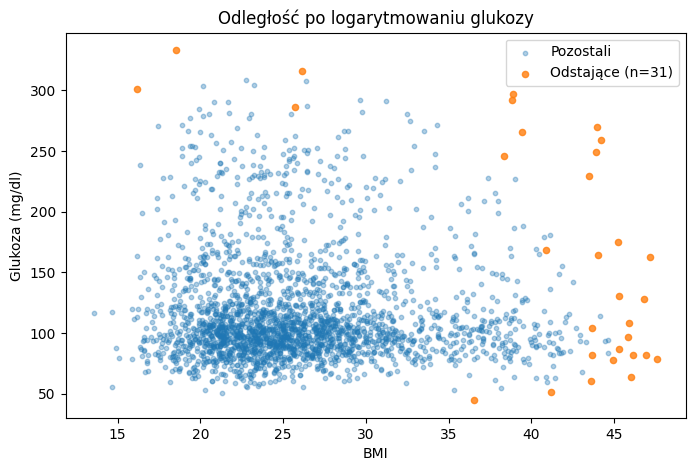

In [30]:
# TODO: X_log, Z_log, d2_log i liczba odstających
X_log = X.copy()
X_log["avg_glucose_level"] = np.log(X_log["avg_glucose_level"])
Z_log = (X_log - X_log.mean()) / X_log.std()
d2_log = Z_log.pow(2).sum(axis=1)
odstajace_log = d2_log > prog
print("Odstające bez log:", odstajace_d2.sum())
print("Odstające po log:", odstajace_log.sum())

# TODO: wykres punktowy
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(X.loc[~odstajace_log, "bmi"], X.loc[~odstajace_log, "avg_glucose_level"],
           s=10, alpha=.35, label="Pozostali")
ax.scatter(X.loc[odstajace_log, "bmi"], X.loc[odstajace_log, "avg_glucose_level"],
           s=20, alpha=.8, label=f"Odstające (n={odstajace_log.sum()})")
ax.set(title="Odległość po logarytmowaniu glukozy", xlabel="BMI", ylabel="Glukoza (mg/dl)")
ax.legend()
plt.show()

✍️ **Pytanie:** Wiek, BMI i glukoza są tu prawie nieskorelowane (sprawdź `X.corr()`). Czy w takiej sytuacji odległość Mahalanobisa dałaby coś więcej niż euklidesowa?

*Odpowiedź:* X.corr() pokazuje siłę korelacji cech. Gdy korelacje są bliskie zeru, odległość po standaryzacji daje wyniki zbliżone do odległości euklidesowej; większą korzyść daje przy wyraźnie skorelowanych zmiennych.

### Dla chętnych: Isolation Forest

Użyj `sklearn.ensemble.IsolationForest` (`contamination=0.01`, `random_state=0`) na `X_log`. Ilu pacjentów wskazuje jednocześnie Isolation Forest i odległość `d2_log`?

In [ ]:
# TODO (dla chętnych)


## 2.6 Krok 5: podsumowanie i decyzja

Zbierz wyniki wszystkich kroków w jednej ramce `flagi` (jeden wiersz na pacjenta, indeks jak w `oryginal`) z kolumnami logicznymi:

- `niemozliwa_wartosc` (krok 1),
- `glukoza_iqr` (krok 2, IQR 1,5 dla glukozy),
- `nielogiczna_kategoria` (krok 3),
- `odlegly_od_srodka` (krok 4, `d2_log`; pacjenci bez obliczonej odległości → `False`).

Policz, ilu pacjentów ma każdą flagę i ilu ma co najmniej jedną.

In [31]:
# TODO: ramka flagi
flagi = pd.DataFrame(index=oryginal.index)
flagi["niemozliwa_wartosc"] = niemozliwe.reindex(flagi.index, fill_value=False)
flagi["glukoza_iqr"] = m_glukoza.reindex(flagi.index, fill_value=False)
flagi["nielogiczna_kategoria"] = (dziecko_pali | maluch_student).reindex(flagi.index, fill_value=False)
flagi["odlegly_od_srodka"] = odstajace_log.reindex(flagi.index, fill_value=False)
flagi = flagi.fillna(False).astype(bool)
print("Liczba pacjentów z każdą flagą:")
print(flagi.sum())
print("Z co najmniej jedną flagą:", flagi.any(axis=1).sum())
print(flagi.head())


Liczba pacjentów z każdą flagą:
niemozliwa_wartosc       560
glukoza_iqr              235
nielogiczna_kategoria     16
odlegly_od_srodka         31
dtype: int64
Z co najmniej jedną flagą: 806
   niemozliwa_wartosc  glukoza_iqr  nielogiczna_kategoria  odlegly_od_srodka
0               False        False                  False              False
1               False        False                  False              False
2               False        False                  False              False
3               False        False                  False              False
4               False        False                  False              False


✍️ **Decyzja:** dla każdej grupy zaproponuj strategię i uzasadnij ją jednym zdaniem.

| Grupa | Strategia (poprawić / NaN / usunąć / przyciąć / log / zostawić / flaga) | Uzasadnienie |
|---|---|---|
| wartości niemożliwe | … | … |
| wysoka glukoza (IQR) | … | … |
| nielogiczne kategorie | … | … |
| odlegli od środka | … | … |